In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_DIR = "../data/troupe/TLS"

In [4]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [5]:
t_id = 9
t = data[t_id]
t.describe()


Number of leaf nodes:	295
Total number of nodes:	589
Rooted:	Yes
Most distant node:	ACCCTTGTCTGAGTCA-1
Max. distance:	0.993565


In [6]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [7]:
T = ete_to_nx(t)
T

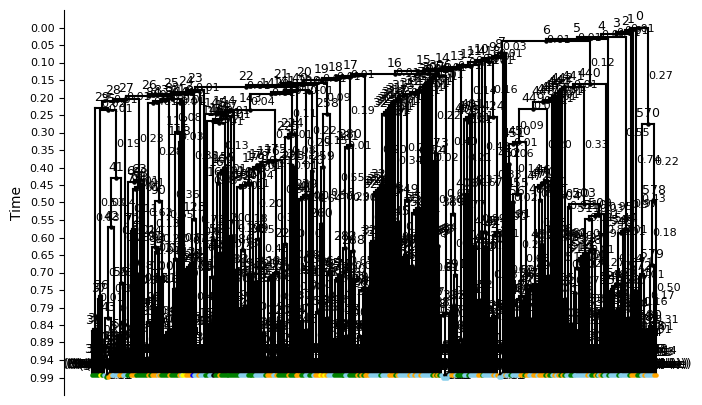

In [8]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'])

In [9]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [10]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [11]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9871282393092302 0.993564891953073


In [12]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [13]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [14]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

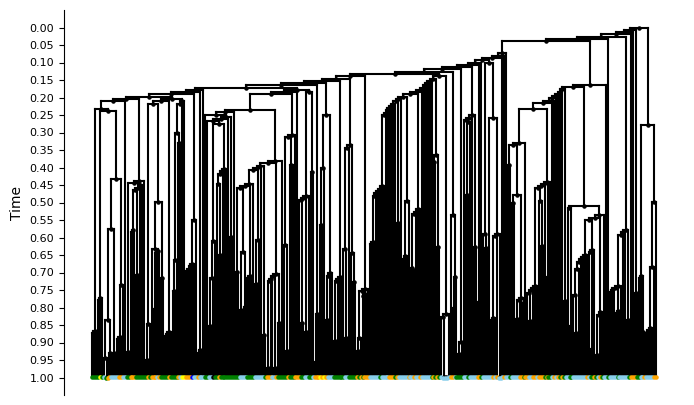

In [15]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [16]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [17]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999 1.0


In [20]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 0.00651831030551374}), (0, 570, {'weight': 0.2774189236243836}), (1, 2, {'weight': 0.006518300494281131}), (1, 567, {'weight': 0.7510387246786251}), (2, 3, {'weight': 0.0065182728065567}), (2, 566, {'weight': 0.9868638522018511}), (3, 4, {'weight': 0.00651818892554842}), (3, 565, {'weight': 0.9803455192977238}), (4, 5, {'weight': 0.006518153799910179}), (4, 544, {'weight': 0.5530527480555016}), (5, 6, {'weight': 0.006518156262138246}), (5, 543, {'weight': 0.9673092298743694}), (6, 7, {'weight': 0.03498968189025969}), (6, 440, {'weight': 0.12429165501778262}), (7, 8, {'weight': 0.006518070842744741}), (7, 439, {'weight': 0.9258013468625031}), (8, 9, {'weight': 0.006518033065910353}), (8, 438, {'weight': 0.9192832787048727}), (9, 10, {'weight': 0.006518029365886656}), (9, 437, {'weight': 0.9127652660767657}), (10, 11, {'weight': 0.00651801464084393}), (10, 418, {'weight': 0.006518380711415644}), (11, 12, {'weight': 0.0065180452424398625}), (11, 417, {'w

In [21]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def plot_ltt(
    T,
    root=None,
    weight_key='weight',
    normalize_time=False,
    reverse_time=False,
    log_scale=True,
    ax=None
):
    """
    Plot Lineage-Through-Time (LTT) curve from a tree.

    Parameters
    ----------
    T : networkx.Graph or DiGraph
        Tree with edge weights
    root : node (optional)
        Root node. If None, inferred automatically.
    weight_key : str
        Edge attribute storing branch length
    normalize_time : bool
        Scale time to [0, 1]
    reverse_time : bool
        Flip time axis (present -> past)
    log_scale : bool
        Use log scale for y-axis
    ax : matplotlib axis (optional)

    Returns
    -------
    times : np.ndarray
    lineages : np.ndarray
    """

    # --- Ensure directed tree ---
    if not nx.is_directed(T):
        if root is None:
            root = list(T.nodes)[0]
        T = nx.bfs_tree(T, root)

    # --- Find root if not given ---
    if root is None:
        root = [n for n in T.nodes if T.in_degree(n) == 0][0]

    # --- Compute node times ---
    node_times = {}

    def dfs(node, current_time):
        node_times[node] = current_time
        for child in T.successors(node):
            w = T.edges[node, child].get(weight_key, 0.0)
            dfs(child, current_time + w)

    dfs(root, 0.0)

    # --- Extract branching times ---
    branching_times = [
        node_times[n]
        for n in T.nodes
        if T.out_degree(n) >= 2
    ]

    branching_times = np.sort(branching_times)

    # --- Build LTT ---
    times = np.insert(branching_times, 0, 0.0)
    lineages = np.arange(1, len(times) + 1)

    # --- Normalize time ---
    if normalize_time:
        max_time = max(node_times.values())
        if max_time > 0:
            times = times / max_time

    # --- Reverse time ---
    if reverse_time:
        max_time = max(times)
        times = max_time - times

    # --- Plot ---
    if ax is None:
        fig, ax = plt.subplots()

    ax.step(times, lineages, where='post')

    ax.set_xlabel("Time")
    ax.set_ylabel("Number of lineages")

    if log_scale:
        ax.set_yscale("log")

    ax.set_title("Lineage Through Time (LTT)")

    return times, lineages

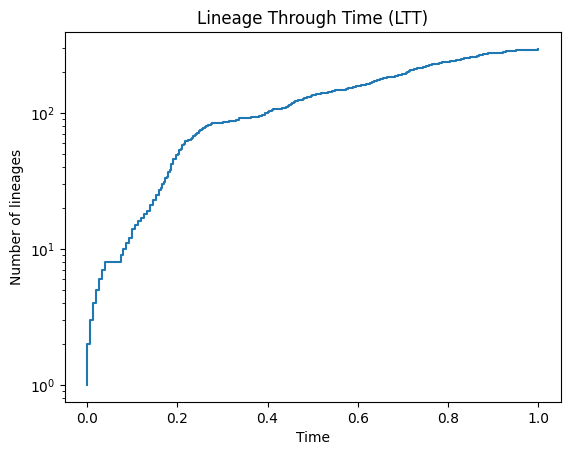

In [22]:
times, lineages = plot_ltt(T)
plt.show()

## For all trees

In [ ]:
def load_and_plot_ltt(tree_id):
    t = data[tree_id]
    T = ete_to_nx(t)
    plot_ltt(T)
    plt.title(f"Tree ID: {tree_id}")
    plt.show()

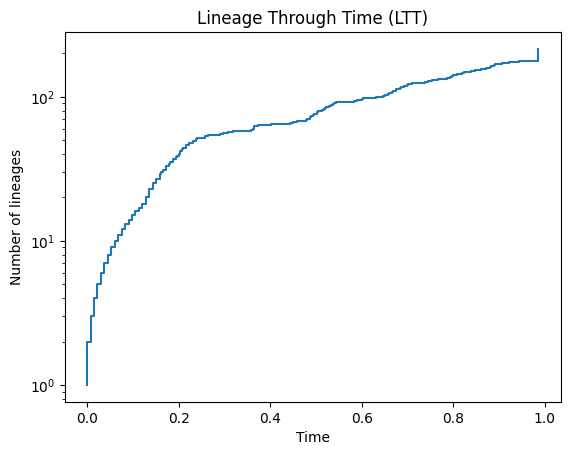

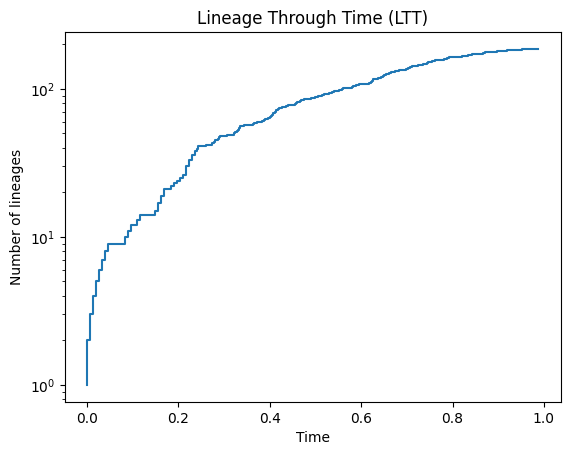

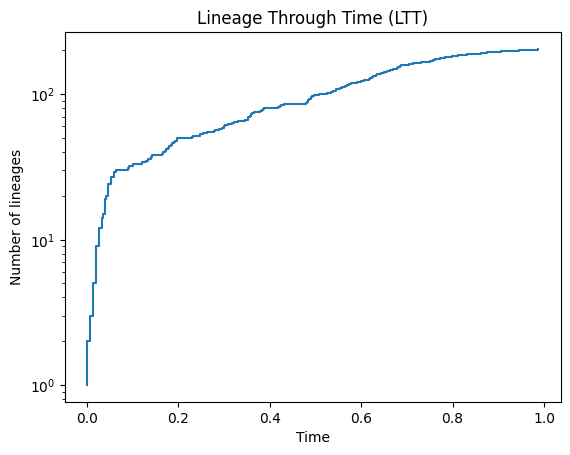

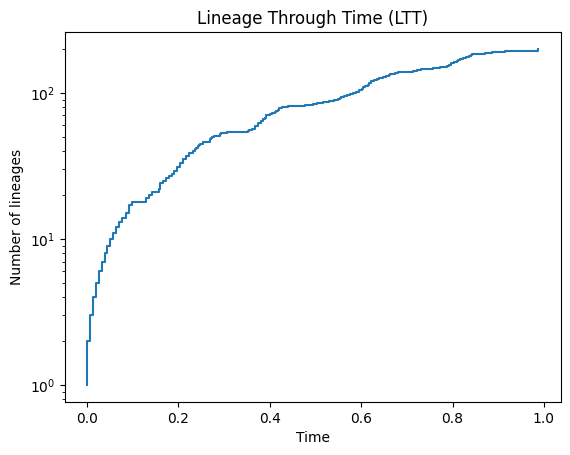

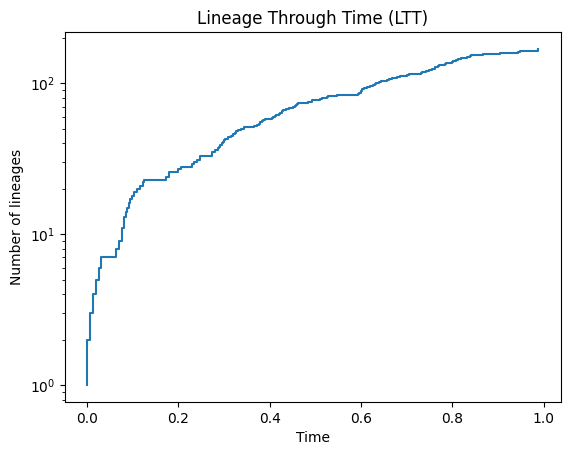

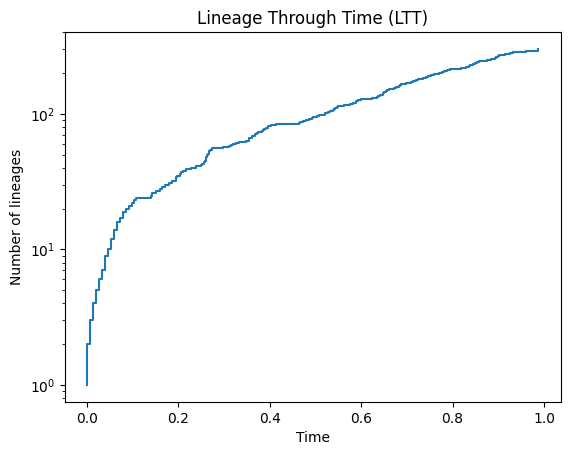

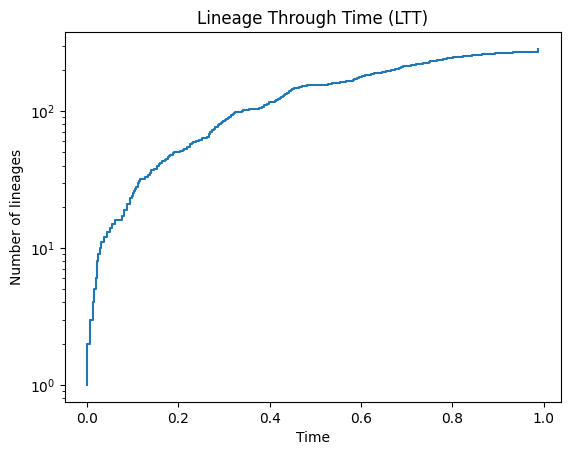

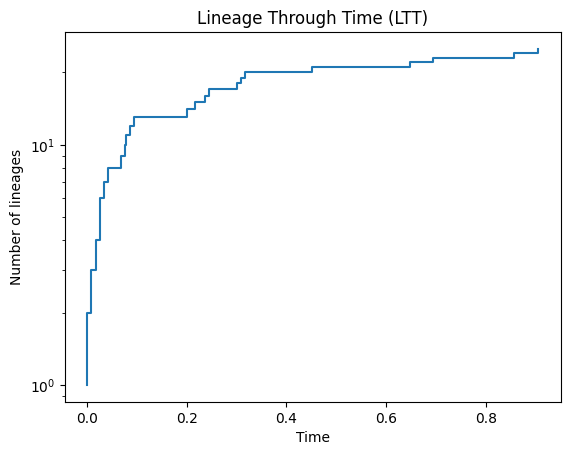

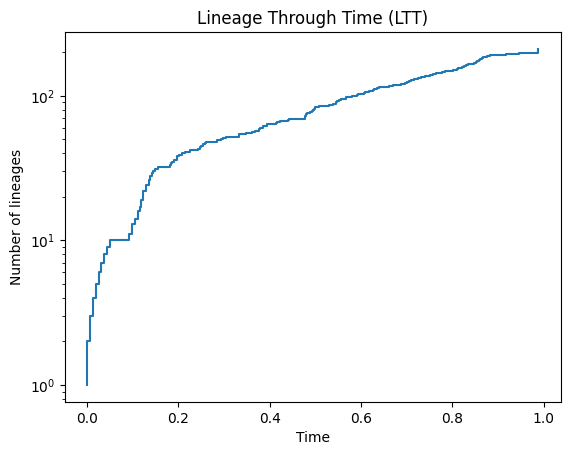

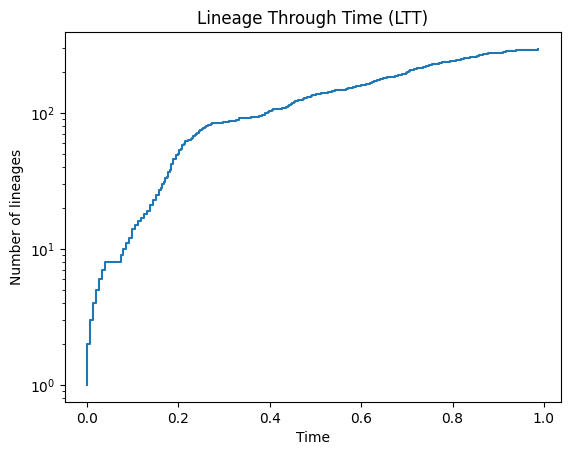

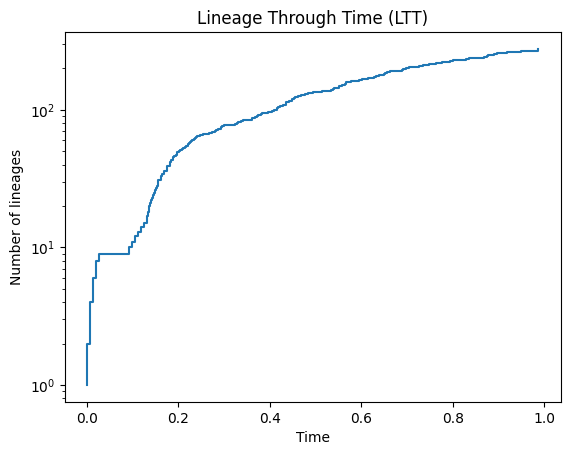

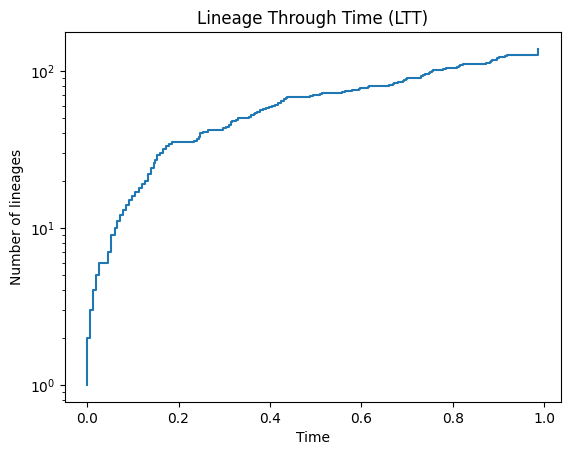

In [28]:
for i in range(12):
    load_and_plot_ltt(i)

In [38]:
def plot_multiple_ltts(
    tree_ids,
    data,
    ete_to_nx,
    weight_key='weight',
    normalize_time=False,
    reverse_time=False,
    log_scale=True
):
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots()

    for tree_id in tree_ids:
        t = data[tree_id]
        T = ete_to_nx(t)

        times, lineages = plot_ltt(
            T,
            weight_key=weight_key,
            normalize_time=normalize_time,
            reverse_time=reverse_time,
            log_scale=log_scale,
            ax=ax
        )

        # Optional: label each curve
        ax.step(times, lineages, where='post', label=str(tree_id))

    ax.set_xlabel("Time")
    ax.set_ylabel("Number of lineages")

    if log_scale:
        ax.set_yscale("log")

    ax.set_title("Lineage Through Time (Multiple Trees)")
    ax.legend()

    plt.show()

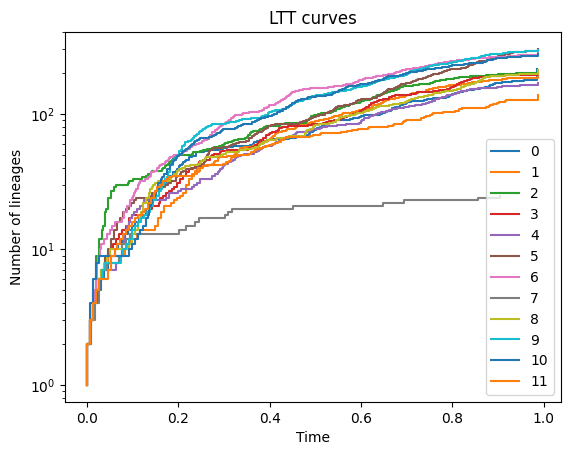

In [45]:
fig, ax = plt.subplots()

for tree_id in range(12):
    t = data[tree_id]
    T = ete_to_nx(t)
    plot_ltt(T, ax=ax)

plt.title("LTT curves")
plt.legend([str(i) for i in range(14)])
plt.show()

In [43]:
import numpy as np
import matplotlib.pyplot as plt

def plot_combined_ltt(tree_ids, data, ete_to_nx, weight_key='weight'):
    """
    Plot a single LTT curve combining all branching events from multiple trees.
    """
    all_branching_times = []

    # 1. Collect branching times from all trees
    for tree_id in tree_ids:
        T = ete_to_nx(data[tree_id])
        
        # Identify root
        root = [n for n in T.nodes if T.in_degree(n) == 0][0]
        
        # Compute node times
        node_times = {}
        def dfs(node, current_time):
            node_times[node] = current_time
            for child in T.successors(node):
                w = T.edges[node, child].get(weight_key, 0.0)
                dfs(child, current_time + w)
        dfs(root, 0.0)
        
        # Collect internal nodes as branching events
        branching_times = [node_times[n] for n in T.nodes if T.out_degree(n) >= 2]
        all_branching_times.extend(branching_times)
    
    # 2. Sort all branching times
    all_branching_times = np.sort(all_branching_times)
    
    # 3. Build LTT
    times = np.insert(all_branching_times, 0, 0.0)
    lineages = np.arange(1, len(times) + 1)
    
    # 4. Plot
    plt.figure()
    plt.step(times, lineages, where='post')
    plt.xlabel("Time from root")
    plt.ylabel("Number of lineages")
    plt.title("Combined LTT Curve (All Trees)")
    plt.yscale("log")
    plt.show()

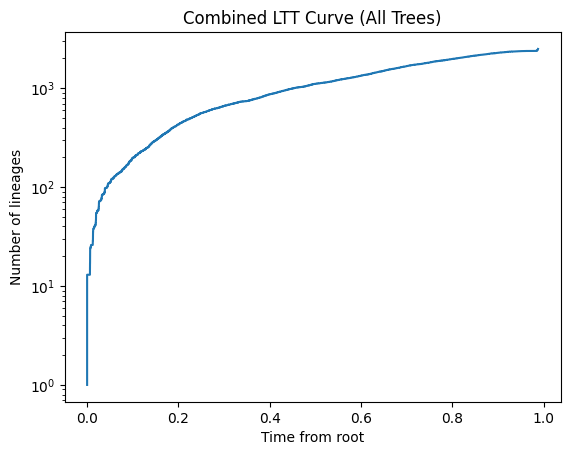

In [44]:
tree_ids = range(12)
plot_combined_ltt(tree_ids, data, ete_to_nx)